# Baseline Models - Cris


#  Regresión logística

## Imports

In [1]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
import pandas as pd
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)
import sys
print(sys.executable)

import mlflow
print("MLflow:", mlflow.__version__)

mlflow.set_tracking_uri("http://127.0.0.1:5000")
mlflow.set_experiment("bank-marketing-baseline-reglog")

print("Tracking URI:", mlflow.get_tracking_uri())

C:\Users\juand\anaconda3\envs\cdt-prueba\python.exe
MLflow: 3.18.0


2026/11/08 19:01:17 INFO mlflow.tracking.fluent: Experiment with name 'bank-marketing-baseline-reglog' does not exist. Creating a new experiment.


Tracking URI: http://127.0.0.1:5000


## Carga y revisión de matrices

In [2]:
from pathlib import Path

# Posibles ubicaciones de los archivos procesados
rutas_posibles = [
    Path("../data/processed"),
    Path("data/processed"),
]

RUTA_PROCESADOS = next(
    (ruta.resolve() for ruta in rutas_posibles if ruta.exists()),
    None
)

if RUTA_PROCESADOS is None:
    raise FileNotFoundError(
        "No se encontró la carpeta data/processed. "
        "Revisa la ubicación de los archivos procesados."
    )

print("Carpeta de archivos procesados:")
print(RUTA_PROCESADOS)

archivos_requeridos = [
    "X_train_final.csv",
    "X_test_final.csv",
    "y_train.csv",
    "y_test.csv",
]

for archivo in archivos_requeridos:
    ruta = RUTA_PROCESADOS / archivo
    print(f"{archivo}: {'Encontrado' if ruta.exists() else 'NO encontrado'}")
    
X_train = pd.read_csv(RUTA_PROCESADOS / "X_train_final.csv")
X_test = pd.read_csv(RUTA_PROCESADOS / "X_test_final.csv")

y_train = pd.read_csv(RUTA_PROCESADOS / "y_train.csv").squeeze()
y_test = pd.read_csv(RUTA_PROCESADOS / "y_test.csv").squeeze()

print("Dimensiones")
print("-----------")
print("X_train:", X_train.shape)
print("X_test: ", X_test.shape)
print("y_train:", y_train.shape)
print("y_test: ", y_test.shape)

print("\nDistribución de y_train:")
print(y_train.value_counts().sort_index())

print("\nDistribución porcentual de y_train:")
print(y_train.value_counts(normalize=True).sort_index().round(4))

print("\nDistribución de y_test:")
print(y_test.value_counts().sort_index())

Carpeta de archivos procesados:
C:\Users\juand\OneDrive\Desktop\priorizacion-clientes-cdt\notebooks\data\processed
X_train_final.csv: Encontrado
X_test_final.csv: Encontrado
y_train.csv: Encontrado
y_test.csv: Encontrado
Dimensiones
-----------
X_train: (36168, 94)
X_test:  (9043, 94)
y_train: (36168,)
y_test:  (9043,)

Distribución de y_train:
y
0    31937
1     4231
Name: count, dtype: int64

Distribución porcentual de y_train:
y
0    0.883
1    0.117
Name: proportion, dtype: float64

Distribución de y_test:
y
0    7985
1    1058
Name: count, dtype: int64


## Crear y entrenar los dos modelos

In [3]:
# Modelo 1: Regresión Logística sin ponderación
modelo_reglog_base = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

# Modelo 2: Regresión Logística con ponderación balanceada
modelo_reglog_balanced = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

# Entrenamiento
modelo_reglog_base.fit(X_train, y_train)
modelo_reglog_balanced.fit(X_train, y_train)

print("Ambos modelos fueron entrenados correctamente.")

Ambos modelos fueron entrenados correctamente.


## Crear una función de evaluación

In [4]:
def evaluar_modelo(nombre, modelo, X, y):
    """
    Evalúa un modelo de clasificación binaria.
    La clase positiva es y = 1 (suscripción).
    """

    # Predicción con umbral estándar de 0.5
    y_pred = modelo.predict(X)

    # Probabilidad estimada de la clase positiva
    y_prob = modelo.predict_proba(X)[:, 1]

    # Métricas generales
    resultados = {
        "Modelo": nombre,
        "Accuracy": accuracy_score(y, y_pred),
        "Precision": precision_score(y, y_pred, zero_division=0),
        "Recall": recall_score(y, y_pred, zero_division=0),
        "F1": f1_score(y, y_pred, zero_division=0),
        "PR_AUC": average_precision_score(y, y_prob),
        "ROC_AUC": roc_auc_score(y, y_prob)
    }

    # Métricas de priorización
    prevalencia = y.mean()

    ranking = pd.DataFrame({
        "real": np.asarray(y),
        "probabilidad": y_prob
    }).sort_values("probabilidad", ascending=False)

    for k in [0.10, 0.20]:
        n_top = max(1, int(np.ceil(len(ranking) * k)))
        top_k = ranking.head(n_top)

        precision_k = top_k["real"].mean()
        lift_k = precision_k / prevalencia if prevalencia > 0 else np.nan

        resultados[f"Precision@{int(k*100)}%"] = precision_k
        resultados[f"Lift@{int(k*100)}%"] = lift_k

    return resultados

## Ejecutar la evaluación en el conjunto de prueba

In [5]:
resultados_base = evaluar_modelo(
    nombre="Regresión Logística - Sin ponderación",
    modelo=modelo_reglog_base,
    X=X_test,
    y=y_test
)

resultados_balanced = evaluar_modelo(
    nombre="Regresión Logística - Balanced",
    modelo=modelo_reglog_balanced,
    X=X_test,
    y=y_test
)

tabla_resultados_reglog = pd.DataFrame([
    resultados_base,
    resultados_balanced
])

tabla_resultados_reglog

,Modelo,Accuracy,Precision,Recall,F1,PR_AUC,ROC_AUC,Precision@10%,Lift@10%,Precision@20%,Lift@20%
0,Regresión Logística - Sin ponderación,0.892845,0.680162,0.158790,0.257471,0.372757,0.738375,0.436464,3.730572,0.299613,2.56087
1,Regresión Logística - Balanced,0.737034,0.243590,0.592628,0.345264,0.371897,0.737952,0.439779,3.758905,0.299613,2.56087


## Ver la matriz de confusión y el reporte

In [6]:
for nombre, modelo in [
    ("Regresión Logística - Sin ponderación", modelo_reglog_base),
    ("Regresión Logística - Balanced", modelo_reglog_balanced)
]:
    print("=" * 80)
    print(nombre)
    print("=" * 80)

    y_pred = modelo.predict(X_test)

    print("\nMatriz de confusión:")
    print(confusion_matrix(y_test, y_pred))

    print("\nReporte de clasificación:")
    print(classification_report(
        y_test,
        y_pred,
        target_names=["No suscribe", "Sí suscribe"],
        zero_division=0
    ))

Regresión Logística - Sin ponderación

Matriz de confusión:
[[7906   79]
 [ 890  168]]

Reporte de clasificación:
              precision    recall  f1-score   support

 No suscribe       0.90      0.99      0.94      7985
 Sí suscribe       0.68      0.16      0.26      1058

    accuracy                           0.89      9043
   macro avg       0.79      0.57      0.60      9043
weighted avg       0.87      0.89      0.86      9043

Regresión Logística - Balanced

Matriz de confusión:
[[6038 1947]
 [ 431  627]]

Reporte de clasificación:
              precision    recall  f1-score   support

 No suscribe       0.93      0.76      0.84      7985
 Sí suscribe       0.24      0.59      0.35      1058

    accuracy                           0.74      9043
   macro avg       0.59      0.67      0.59      9043
weighted avg       0.85      0.74      0.78      9043



## Corregir y verificar Precision@K y Lift@K

In [7]:
def calcular_metricas_ranking(y_real, y_prob, porcentajes=(0.10, 0.20)):
    ranking = pd.DataFrame({
        "real": np.asarray(y_real),
        "probabilidad": np.asarray(y_prob)
    }).sort_values("probabilidad", ascending=False)

    prevalencia = ranking["real"].mean()
    resultados = []

    for porcentaje in porcentajes:
        n_top = int(np.ceil(len(ranking) * porcentaje))
        top_k = ranking.head(n_top)

        precision_k = top_k["real"].mean()
        lift_k = precision_k / prevalencia

        resultados.append({
            "Porcentaje": f"Top {porcentaje:.0%}",
            "Clientes seleccionados": n_top,
            "Positivos encontrados": int(top_k["real"].sum()),
            "Precision@K": precision_k,
            "Lift@K": lift_k
        })

    return pd.DataFrame(resultados)


for nombre, modelo in [
    ("Regresión Logística - Sin ponderación", modelo_reglog_base),
    ("Regresión Logística - Balanced", modelo_reglog_balanced)
]:
    probabilidades = modelo.predict_proba(X_test)[:, 1]

    print(f"\n{nombre}")
    display(
        calcular_metricas_ranking(y_test, probabilidades)
        .style.format({
            "Precision@K": "{:.3f}",
            "Lift@K": "{:.3f}"
        })
    )


Regresión Logística - Sin ponderación


,Porcentaje,Clientes seleccionados,Positivos encontrados,Precision@K,Lift@K
0,Top 10%,905,395,0.436,3.731
1,Top 20%,1809,542,0.300,2.561



Regresión Logística - Balanced


,Porcentaje,Clientes seleccionados,Positivos encontrados,Precision@K,Lift@K
0,Top 10%,905,398,0.440,3.759
1,Top 20%,1809,542,0.300,2.561


Precision@K: proporción de clientes que sí suscribieron dentro del segmento superior del ranking.
Lift@K: Precision@K dividida por la proporción de positivos en toda la población de prueba.

## Crear un conjunto interno de validación

In [8]:
from sklearn.model_selection import train_test_split

X_train_model, X_val = train_test_split(
    X_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

y_train_model = y_train.loc[X_train_model.index]
y_val = y_train.loc[X_val.index]

print("Entrenamiento interno:", X_train_model.shape)
print("Validación:", X_val.shape)

print("\nDistribución de y_train_model:")
print(y_train_model.value_counts(normalize=True).round(4))

print("\nDistribución de y_val:")
print(y_val.value_counts(normalize=True).round(4))

Entrenamiento interno: (28934, 94)
Validación: (7234, 94)

Distribución de y_train_model:
y
0    0.883
1    0.117
Name: proportion, dtype: float64

Distribución de y_val:
y
0    0.8831
1    0.1169
Name: proportion, dtype: float64


## Entrenar las dos variantes solo con el entrenamiento interno

In [9]:
modelo_reglog_base_val = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

modelo_reglog_balanced_val = Pipeline(steps=[
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

modelo_reglog_base_val.fit(X_train_model, y_train_model)
modelo_reglog_balanced_val.fit(X_train_model, y_train_model)

print("Modelos entrenados para análisis de umbral.")

Modelos entrenados para análisis de umbral.


## Comparar umbrales sobre validación

In [10]:
def evaluar_umbrales(nombre, modelo, X, y, umbrales=None):
    if umbrales is None:
        umbrales = [0.20, 0.25, 0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]

    probabilidades = modelo.predict_proba(X)[:, 1]
    resultados = []

    for umbral in umbrales:
        y_pred = (probabilidades >= umbral).astype(int)

        resultados.append({
            "Modelo": nombre,
            "Umbral": umbral,
            "Precision": precision_score(y, y_pred, zero_division=0),
            "Recall": recall_score(y, y_pred, zero_division=0),
            "F1": f1_score(y, y_pred, zero_division=0),
            "Clientes clasificados como yes": int(y_pred.sum())
        })

    return pd.DataFrame(resultados)


tabla_umbrales = pd.concat([
    evaluar_umbrales(
        "RegLog sin ponderación",
        modelo_reglog_base_val,
        X_val,
        y_val
    ),
    evaluar_umbrales(
        "RegLog balanced",
        modelo_reglog_balanced_val,
        X_val,
        y_val
    )
], ignore_index=True)

display(
    tabla_umbrales.style.format({
        "Umbral": "{:.2f}",
        "Precision": "{:.3f}",
        "Recall": "{:.3f}",
        "F1": "{:.3f}"
    })
)

,Modelo,Umbral,Precision,Recall,F1,Clientes clasificados como yes
0,RegLog sin ponderación,0.20,0.434,0.382,0.406,745
1,RegLog sin ponderación,0.25,0.506,0.324,0.395,542
2,RegLog sin ponderación,0.30,0.571,0.261,0.358,387
3,RegLog sin ponderación,0.35,0.600,0.220,0.322,310
4,RegLog sin ponderación,0.40,0.623,0.195,0.297,265
5,RegLog sin ponderación,0.45,0.647,0.177,0.278,232
6,RegLog sin ponderación,0.50,0.654,0.161,0.258,208
7,RegLog sin ponderación,0.55,0.676,0.145,0.239,182
8,RegLog sin ponderación,0.60,0.702,0.125,0.213,151
9,RegLog balanced,0.20,0.118,0.985,0.210,7073


1. Qué nos dicen los resultados

Regresión Logística sin ponderación

El mejor F1 de los umbrales evaluados aparece en 0,20: F1 = 0,406.
- Precision: 0,434
- Recall: 0,382
- Clasifica 745 clientes como positivos
Al aumentar el umbral, la precisión mejora, pero el recall cae. Por ejemplo, con umbral 0,50 la precisión es 0,654, pero el recall solo 0,161. Es una selección más conservadora: predice menos positivos y deja escapar muchos clientes que sí suscribieron.

Regresión Logística balanceada

El mejor F1 de los umbrales evaluados aparece en 0,60: F1 = 0,409.
- Precision: 0,370
- Recall: 0,459
- Clasifica 1.050 clientes como positivos
Con umbrales más bajos, el recall es muy alto, pero también se clasifica una cantidad enorme de clientes como positivos. Por ejemplo, con umbral 0,20 clasifica 7.073 clientes como positivos, con precision de apenas 0,118.
2. Comparación del mejor F1 observado

La diferencia de F1 es pequeña. La versión balanceada, con umbral 0,60, logra un recall algo mayor, pero necesita clasificar más clientes como positivos y tiene menor precision.

Conclusión provisional: no hay un ganador contundente entre las dos variantes de Regresión Logística. La elección dependerá de los resultados de los modelos de árboles y de la capacidad real de llamadas. Para el caso de uso, debemos conservar también las métricas de ranking, no solo F1.

3. Qué dejamos documentado de Regresión Logística

La Regresión Logística se utilizó como modelo baseline para la clasificación de clientes con y sin suscripción a un depósito a plazo. Se compararon versiones sin ponderación y con ponderación balanceada para analizar el efecto del desbalance de clases. La ponderación aumentó el recall al umbral estándar de 0,5, pero redujo la precision y la accuracy. En el análisis de umbrales sobre el conjunto de validación, ambas variantes alcanzaron valores de F1 similares: 0,406 para la versión sin ponderación con umbral 0,20 y 0,409 para la versión balanceada con umbral 0,60. Por tanto, no se identifica aún una variante claramente superior. La selección final se realizará comparando estos resultados con otros modelos y considerando las métricas de priorización de clientes.

Importante: estos umbrales son resultados de validación, no una selección definitiva. El conjunto de prueba queda reservado para la evaluación final cuando comparemos los modelos.

# Configuración del MLFlow

In [11]:
import mlflow

# Nombre del experimento para el baseline
mlflow.set_experiment("bank-marketing-baseline-reglog")

print("Experimento MLflow configurado:")
print("bank-marketing-baseline-reglog")

Experimento MLflow configurado:
bank-marketing-baseline-reglog


### Registro de modelos baseline con MLflow

Se registran dos configuraciones de Regresión Logística: una sin ponderación de clases y otra con `class_weight="balanced"`. Ambas se entrenan con la misma partición interna y se evalúan sobre el mismo conjunto de validación.

Se registran parámetros y métricas de clasificación y ranking para facilitar la comparación reproducible.

In [12]:
modelos_baseline = {
    "reglog_sin_balanceo": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=2000,
            random_state=42
        ))
    ]),
    "reglog_balanceada": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        ))
    ])
}

resultados_mlflow = []

for nombre, modelo in modelos_baseline.items():

    with mlflow.start_run(run_name=nombre):

        # Entrenamiento con la partición interna
        modelo.fit(X_train_model, y_train_model)

        # Predicciones sobre validación
        y_val_pred = modelo.predict(X_val)
        y_val_prob = modelo.predict_proba(X_val)[:, 1]

        # Métricas de clasificación
        precision = precision_score(
            y_val, y_val_pred, zero_division=0
        )
        recall = recall_score(
            y_val, y_val_pred, zero_division=0
        )
        f1 = f1_score(
            y_val, y_val_pred, zero_division=0
        )

        # Métricas de ranking
        pr_auc = average_precision_score(y_val, y_val_prob)
        roc_auc = roc_auc_score(y_val, y_val_prob)

        # Registro de parámetros
        mlflow.log_param("modelo", "LogisticRegression")
        mlflow.log_param(
            "class_weight",
            modelo.named_steps["model"].class_weight
        )
        mlflow.log_param(
            "max_iter",
            modelo.named_steps["model"].max_iter
        )
        mlflow.log_param("random_state", 42)
        mlflow.log_param("threshold", 0.50)

        # Registro de métricas
        mlflow.log_metric("precision", precision)
        mlflow.log_metric("recall", recall)
        mlflow.log_metric("f1", f1)
        mlflow.log_metric("pr_auc", pr_auc)
        mlflow.log_metric("roc_auc", roc_auc)

        # Registro del modelo entrenado
        mlflow.sklearn.log_model(
            sk_model=modelo,
            name="modelo"
        )

        resultados_mlflow.append({
            "modelo": nombre,
            "precision": precision,
            "recall": recall,
            "f1": f1,
            "pr_auc": pr_auc,
            "roc_auc": roc_auc
        })

resultados_mlflow

🏃 View run reglog_sin_balanceo at: http://127.0.0.1:5000/#/experiments/1/runs/c679c0f7aa23434cbdf43aad3737704e
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run reglog_balanceada at: http://127.0.0.1:5000/#/experiments/1/runs/04793888fbd1438881e148c781747468
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


[{'modelo': 'reglog_sin_balanceo',
  'precision': 0.6538461538461539,
  'recall': 0.1607565011820331,
  'f1': 0.25806451612903225,
  'pr_auc': 0.37898831661480886,
  'roc_auc': 0.7442386988902063},
 {'modelo': 'reglog_balanceada',
  'precision': 0.25173783515392256,
  'recall': 0.599290780141844,
  'f1': 0.35454545454545455,
  'pr_auc': 0.37743134820331625,
  'roc_auc': 0.7451322552184874}]

## Crear una función para las métricas de ranking

In [13]:
def metricas_ranking(y_real, probabilidades, k_values=(0.10, 0.20)):
    y_real = np.asarray(y_real)
    probabilidades = np.asarray(probabilidades)

    # Ordenar clientes de mayor a menor probabilidad
    orden = np.argsort(probabilidades)[::-1]

    resultados = {}

    for k in k_values:
        n_clientes = max(1, int(np.ceil(len(y_real) * k)))
        indices_top_k = orden[:n_clientes]

        precision_top_k = y_real[indices_top_k].mean()
        tasa_positivos = y_real.mean()
        lift_top_k = precision_top_k / tasa_positivos

        resultados[f"precision_at_{int(k * 100)}"] = precision_top_k
        resultados[f"lift_at_{int(k * 100)}"] = lift_top_k

    return resultados

## Calcular las métricas para los modelos de validación

In [14]:
# Probabilidades estimadas para la clase positiva (respuesta = 1)
probabilidades_reglog = modelo_reglog_base_val.predict_proba(X_val)[:, 1]
probabilidades_reglog_balanced = modelo_reglog_balanced_val.predict_proba(X_val)[:, 1]

# Métricas de ranking
ranking_reglog = metricas_ranking(y_val, probabilidades_reglog)
ranking_reglog_balanced = metricas_ranking(y_val, probabilidades_reglog_balanced)

print("Regresión logística sin balanceo:")
print(ranking_reglog)

print("\nRegresión logística con balanceo:")
print(ranking_reglog_balanced)

Regresión logística sin balanceo:
{'precision_at_10': np.float64(0.4419889502762431), 'lift_at_10': np.float64(3.7793712367592702), 'precision_at_20': np.float64(0.3075328265376641), 'lift_at_20': np.float64(2.6296601266825794)}

Regresión logística con balanceo:
{'precision_at_10': np.float64(0.44060773480662985), 'lift_at_10': np.float64(3.7675607016443977), 'precision_at_20': np.float64(0.308914996544575), 'lift_at_20': np.float64(2.6414788238811533)}


## Registrar estas métricas en MLflow

In [15]:
with mlflow.start_run(run_name="reglog_sin_balanceo_ranking"):
    mlflow.log_param("modelo", "LogisticRegression")
    mlflow.log_param("class_weight", "None")
    mlflow.log_param("evaluacion", "validacion")

    mlflow.log_metrics(ranking_reglog)

with mlflow.start_run(run_name="reglog_balanceada_ranking"):
    mlflow.log_param("modelo", "LogisticRegression")
    mlflow.log_param("class_weight", "balanced")
    mlflow.log_param("evaluacion", "validacion")

    mlflow.log_metrics(ranking_reglog_balanced)

🏃 View run reglog_sin_balanceo_ranking at: http://127.0.0.1:5000/#/experiments/1/runs/c323d3d976e44b5d88ee2d77f481876c
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run reglog_balanceada_ranking at: http://127.0.0.1:5000/#/experiments/1/runs/5d62e803729f47228372b65dfc1e2fb4
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


# RANDOM FOREST

## Importar y entrenar los modelos

In [16]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score
)

modelo_rf_base = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_leaf=2,
    class_weight=None,
    random_state=42,
    n_jobs=-1
)

modelo_rf_balanced = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_leaf=2,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

modelo_rf_base.fit(X_train_model, y_train_model)
modelo_rf_balanced.fit(X_train_model, y_train_model)

print("Random Forest sin balanceo entrenado.")
print("Random Forest balanceado entrenado.")

Random Forest sin balanceo entrenado.
Random Forest balanceado entrenado.


## Evaluar en validación

In [17]:
def evaluar_modelo_validacion(modelo, X_val, y_val):
    probabilidades = modelo.predict_proba(X_val)[:, 1]
    predicciones = (probabilidades >= 0.5).astype(int)

    metricas = {
        "precision": precision_score(y_val, predicciones, zero_division=0),
        "recall": recall_score(y_val, predicciones, zero_division=0),
        "f1": f1_score(y_val, predicciones, zero_division=0),
        "pr_auc": average_precision_score(y_val, probabilidades),
        "roc_auc": roc_auc_score(y_val, probabilidades)
    }

    metricas.update(
        metricas_ranking(y_val, probabilidades)
    )

    return metricas, probabilidades


metricas_rf_base, probabilidades_rf_base = evaluar_modelo_validacion(
    modelo_rf_base, X_val, y_val
)

metricas_rf_balanced, probabilidades_rf_balanced = evaluar_modelo_validacion(
    modelo_rf_balanced, X_val, y_val
)

print("Random Forest sin balanceo:")
display(pd.DataFrame([metricas_rf_base], index=["RF sin balanceo"]).T)

print("Random Forest balanceado:")
display(pd.DataFrame([metricas_rf_balanced], index=["RF balanceado"]).T)

Random Forest sin balanceo:


,RF sin balanceo
precision,0.622490
recall,0.183215
f1,0.283105
pr_auc,0.379087
roc_auc,0.722321
precision_at_10,0.441989
lift_at_10,3.779371
precision_at_20,0.299931
lift_at_20,2.564657


Random Forest balanceado:


,RF balanceado
precision,0.338739
recall,0.444444
f1,0.384458
pr_auc,0.358906
roc_auc,0.724598
precision_at_10,0.421271
lift_at_10,3.602213
precision_at_20,0.294402
lift_at_20,2.517383


## Registrar las ejecuciones en MLflow

In [18]:
with mlflow.start_run(run_name="random_forest_sin_balanceo_v2"):
    mlflow.log_params({
        "modelo": "RandomForestClassifier",
        "class_weight": "None",
        "n_estimators": 300,
        "max_depth": "None",
        "min_samples_leaf": 2,
        "evaluacion": "validacion"
    })

    mlflow.log_metrics(metricas_rf_base)

    mlflow.sklearn.log_model(
        sk_model=modelo_rf_base,
        name="random_forest_sin_balanceo",
        skops_trusted_types=["sklearn.tree._tree.Tree"]
    )


with mlflow.start_run(run_name="random_forest_balanceado_v2"):
    mlflow.log_params({
        "modelo": "RandomForestClassifier",
        "class_weight": "balanced",
        "n_estimators": 300,
        "max_depth": "None",
        "min_samples_leaf": 2,
        "evaluacion": "validacion"
    })

    mlflow.log_metrics(metricas_rf_balanced)

    mlflow.sklearn.log_model(
        sk_model=modelo_rf_balanced,
        name="random_forest_balanceado",
        skops_trusted_types=["sklearn.tree._tree.Tree"]
    )

🏃 View run random_forest_sin_balanceo_v2 at: http://127.0.0.1:5000/#/experiments/1/runs/ad4fd205756048efa6a0edddbe0fe739
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
🏃 View run random_forest_balanceado_v2 at: http://127.0.0.1:5000/#/experiments/1/runs/6e8fb928b73c4699b87c3e915e59c7ea
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


## Entrenar dos variantes

In [19]:
from sklearn.ensemble import GradientBoostingClassifier

modelo_gb_base = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

modelo_gb_base.fit(X_train_model, y_train_model)

print("Gradient Boosting sin balanceo entrenado.")

Gradient Boosting sin balanceo entrenado.


## Evaluar en validación

In [20]:
metricas_gb_base, probabilidades_gb_base = evaluar_modelo_validacion(
    modelo_gb_base,
    X_val,
    y_val
)

display(
    pd.DataFrame(
        [metricas_gb_base],
        index=["Gradient Boosting"]
    ).T
)

,Gradient Boosting
precision,0.677419
recall,0.173759
f1,0.276576
pr_auc,0.400075
roc_auc,0.746454
precision_at_10,0.466851
lift_at_10,3.991961
precision_at_20,0.312370
lift_at_20,2.671026


## Registrar en MLflow

In [21]:
with mlflow.start_run(run_name="gradient_boosting_base_v2"):
    mlflow.log_params({
        "modelo": "GradientBoostingClassifier",
        "n_estimators": 100,
        "learning_rate": 0.1,
        "max_depth": 3,
        "evaluacion": "validacion"
    })

    mlflow.log_metrics(metricas_gb_base)

    mlflow.sklearn.log_model(
        sk_model=modelo_gb_base,
        name="gradient_boosting_base",
        skops_trusted_types=["sklearn.tree._tree.Tree"]
    )

🏃 View run gradient_boosting_base_v2 at: http://127.0.0.1:5000/#/experiments/1/runs/eb6cb2630e16411f9a76c670409049a5
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1


## Crear una tabla comparativa de validación

In [22]:
metricas_reglog_base, probabilidades_reglog_base = evaluar_modelo_validacion(
    modelo_reglog_base_val,
    X_val,
    y_val
)

metricas_reglog_balanced, probabilidades_reglog_balanced = evaluar_modelo_validacion(
    modelo_reglog_balanced_val,
    X_val,
    y_val
)

print("Regresión logística sin balanceo:")
display(pd.DataFrame([metricas_reglog_base], index=["RegLog sin balanceo"]).T)

print("Regresión logística balanceada:")
display(pd.DataFrame([metricas_reglog_balanced], index=["RegLog balanceada"]).T)

Regresión logística sin balanceo:


,RegLog sin balanceo
precision,0.653846
recall,0.160757
f1,0.258065
pr_auc,0.378988
roc_auc,0.744239
precision_at_10,0.441989
lift_at_10,3.779371
precision_at_20,0.307533
lift_at_20,2.629660


Regresión logística balanceada:


,RegLog balanceada
precision,0.251738
recall,0.599291
f1,0.354545
pr_auc,0.377431
roc_auc,0.745132
precision_at_10,0.440608
lift_at_10,3.767561
precision_at_20,0.308915
lift_at_20,2.641479


In [23]:
resultados_validacion = {
    "RegLog sin balanceo": metricas_reglog_base,
    "RegLog balanceada": metricas_reglog_balanced,
    "Random Forest sin balanceo": metricas_rf_base,
    "Random Forest balanceado": metricas_rf_balanced,
    "Gradient Boosting": metricas_gb_base
}

tabla_comparacion = pd.DataFrame(resultados_validacion).T

columnas_prioritarias = [
    "precision",
    "recall",
    "f1",
    "pr_auc",
    "roc_auc",
    "precision_at_10",
    "lift_at_10",
    "precision_at_20",
    "lift_at_20"
]

tabla_comparacion = tabla_comparacion[columnas_prioritarias]

display(tabla_comparacion.round(4))

,precision,recall,f1,pr_auc,roc_auc,precision_at_10,lift_at_10,precision_at_20,lift_at_20
RegLog sin balanceo,0.6538,0.1608,0.2581,0.3790,0.7442,0.4420,3.7794,0.3075,2.6297
RegLog balanceada,0.2517,0.5993,0.3545,0.3774,0.7451,0.4406,3.7676,0.3089,2.6415
Random Forest sin balanceo,0.6225,0.1832,0.2831,0.3791,0.7223,0.4420,3.7794,0.2999,2.5647
Random Forest balanceado,0.3387,0.4444,0.3845,0.3589,0.7246,0.4213,3.6022,0.2944,2.5174
Gradient Boosting,0.6774,0.1738,0.2766,0.4001,0.7465,0.4669,3.9920,0.3124,2.6710


In [24]:
tabla_comparacion.sort_values(
    by="lift_at_10",
    ascending=False
).round(4)

,precision,recall,f1,pr_auc,roc_auc,precision_at_10,lift_at_10,precision_at_20,lift_at_20
Gradient Boosting,0.6774,0.1738,0.2766,0.4001,0.7465,0.4669,3.9920,0.3124,2.6710
RegLog sin balanceo,0.6538,0.1608,0.2581,0.3790,0.7442,0.4420,3.7794,0.3075,2.6297
Random Forest sin balanceo,0.6225,0.1832,0.2831,0.3791,0.7223,0.4420,3.7794,0.2999,2.5647
RegLog balanceada,0.2517,0.5993,0.3545,0.3774,0.7451,0.4406,3.7676,0.3089,2.6415
Random Forest balanceado,0.3387,0.4444,0.3845,0.3589,0.7246,0.4213,3.6022,0.2944,2.5174


## Conclusión de la comparación

Para el caso de uso —priorizar clientes para una campaña de CDT— se selecciona provisionalmente Gradient Boosting para la evaluación final porque:
- Tiene el mayor PR-AUC (0.4001), que resume el equilibrio entre precisión y recall en distintos umbrales.
- Tiene el mayor Precision@10% (0.4669) y Lift@10% (3.9920).
- También lidera Precision@20% (0.3124) y Lift@20% (2.6710).
- Aunque Random Forest balanceado tiene el mayor F1 con umbral 0.5, no supera a Gradient Boosting en las métricas de priorización.
Esto es una selección preliminar basada en validación, no el resultado final del test.

# Evaluación final con test

In [25]:
# Modelo seleccionado preliminarmente: Gradient Boosting
# Se entrena con todo el conjunto de entrenamiento (80%)

from sklearn.ensemble import GradientBoostingClassifier

modelo_gb_final = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

modelo_gb_final.fit(X_train, y_train)

print("Gradient Boosting final entrenado con todo X_train.")
print("Filas utilizadas:", X_train.shape[0])
print("Número de variables:", X_train.shape[1])

Gradient Boosting final entrenado con todo X_train.
Filas utilizadas: 36168
Número de variables: 94


In [26]:
# Evaluación final: usar el test reservado
metricas_gb_test, probabilidades_gb_test = evaluar_modelo_validacion(
    modelo_gb_final,
    X_test,
    y_test
)

print("Métricas finales de Gradient Boosting en TEST:")
display(
    pd.DataFrame(
        [metricas_gb_test],
        index=["Gradient Boosting - TEST"]
    ).T
)

Métricas finales de Gradient Boosting en TEST:


,Gradient Boosting - TEST
precision,0.693798
recall,0.169187
f1,0.272036
pr_auc,0.389721
roc_auc,0.741193
precision_at_10,0.443094
lift_at_10,3.787239
precision_at_20,0.301271
lift_at_20,2.575045


In [27]:
with mlflow.start_run(run_name="gradient_boosting_final_test_v2"):
    mlflow.log_params({
        "modelo": "GradientBoostingClassifier",
        "n_estimators": 100,
        "learning_rate": 0.1,
        "max_depth": 3,
        "evaluacion": "test",
        "modelo_seleccionado": "Gradient Boosting",
        "criterio_seleccion": "PR-AUC y métricas de ranking en validación"
    })

    mlflow.log_metrics({
        f"test_{nombre}": float(valor)
        for nombre, valor in metricas_gb_test.items()
    })

    mlflow.sklearn.log_model(
        sk_model=modelo_gb_final,
        name="gradient_boosting_final",
        skops_trusted_types=["sklearn.tree._tree.Tree"]
    )

print("Evaluación final registrada en MLflow.")

🏃 View run gradient_boosting_final_test_v2 at: http://127.0.0.1:5000/#/experiments/1/runs/3d60a7a8357e475fb1517de8209c518c
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/1
Evaluación final registrada en MLflow.


El modelo Gradient Boosting obtuvo una PR-AUC de 0.3897 y una ROC-AUC de 0.7412 en el conjunto de prueba. Aunque el recall con el umbral predeterminado de 0.5 es moderado (16.92%), el modelo muestra utilidad para priorizar clientes según su probabilidad estimada de suscripción.

Al seleccionar el 10% de clientes con mayor puntuación, la precisión alcanza 44.31%, aproximadamente 3.79 veces la tasa de suscripción de la población evaluada. Si se selecciona el 20% superior, la precisión es 30.13%, con un lift de 2.58×.

Esto respalda un enfoque de priorización por capacidad de contacto, en lugar de depender únicamente de una clasificación binaria con umbral 0.5. Los resultados no garantizan que una campaña real produzca el mismo desempeño; deben validarse operativamente.

## Interpretabilidad del modelo seleccionado

,importancia
cat__poutcome_success,0.271762
num__previous_success,0.229323
num__days_since_previous_contact_log,0.074813
num__age,0.051784
num__days_since_previous_contact,0.051138
num__age_log,0.044467
num__active_loan_products_count,0.043498
num__has_any_loan,0.042671
num__balance,0.021977
num__age_squared_log,0.018732


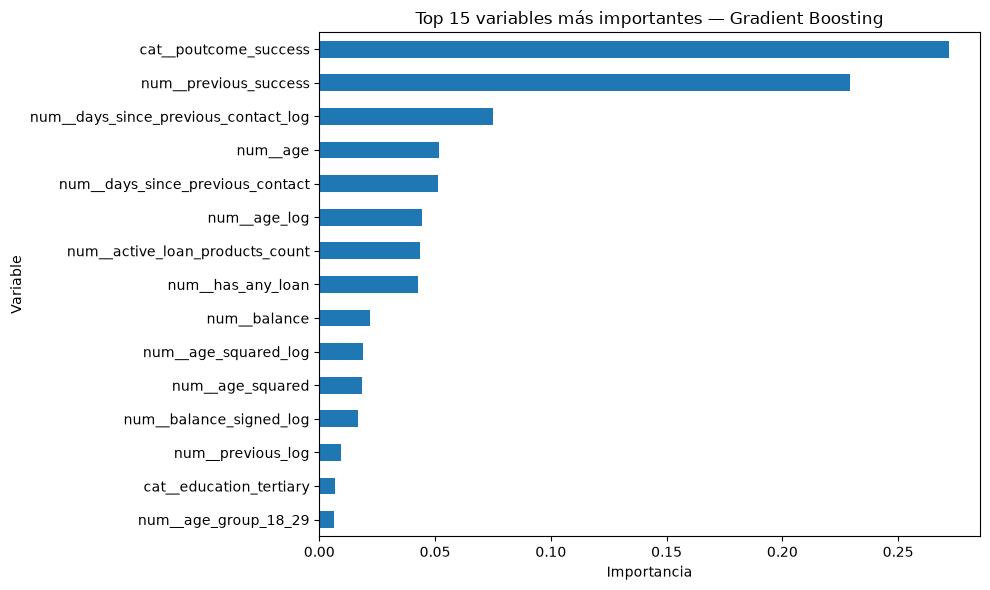

In [28]:
import matplotlib.pyplot as plt

importancias = pd.Series(
    modelo_gb_final.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

top_15_importancias = importancias.head(15)

display(
    top_15_importancias
    .rename("importancia")
    .to_frame()
)

plt.figure(figsize=(10, 6))
top_15_importancias.sort_values().plot(kind="barh")
plt.title("Top 15 variables más importantes — Gradient Boosting")
plt.xlabel("Importancia")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()

### Interpretación de resultados

La importancia de variables del modelo Gradient Boosting muestra que las variables relacionadas con campañas anteriores concentran la mayor contribución predictiva. En particular, `cat__poutcome_success` presenta una importancia de 0.2718, seguida de `num__previous_success`, con 0.2293. En conjunto, ambas representan aproximadamente el 50.1% de la importancia total del modelo.

También destacan el tiempo transcurrido desde el contacto anterior, la edad y las variables relacionadas con productos de crédito y balance. La presencia de variables originales y transformadas —por ejemplo, edad y edad logarítmica— refleja que el modelo puede aprovechar distintas representaciones de una misma característica.

Estos resultados describen la contribución de las variables a las predicciones del modelo, pero no establecen relaciones causales. Además, la importancia elevada de variables de campañas previas debe interpretarse considerando que su disponibilidad y significado operacional deben verificarse al momento de priorizar clientes para una nueva campaña.

## GUARDAR MODELOS ENTRENADOS EN FORMATO PKL

In [30]:
from pathlib import Path
import pickle
import sklearn
import mlflow

# Carpeta de salida en la raíz del proyecto
CARPETA_MODELOS = Path("../models")
CARPETA_MODELOS.mkdir(parents=True, exist_ok=True)

# Modelos entrenados disponibles en este notebook
modelos_a_guardar = {
    "regresion_logistica_sin_balanceo": modelo_reglog_base,
    "regresion_logistica_balanceada": modelo_reglog_balanced,
    "random_forest_sin_balanceo": modelo_rf_base,
    "random_forest_balanceado": modelo_rf_balanced,
    "gradient_boosting_base": modelo_gb_base,
    "gradient_boosting_final": modelo_gb_final,
}

# Guardar cada modelo
for nombre, modelo in modelos_a_guardar.items():
    ruta_modelo = CARPETA_MODELOS / f"{nombre}.pkl"

    with open(ruta_modelo, "wb") as archivo:
        pickle.dump(modelo, archivo)

    print(f"Modelo guardado: {ruta_modelo.resolve()}")

# Guardar versiones de librerías para reproducibilidad
metadata_modelos = {
    "scikit_learn": sklearn.__version__,
    "mlflow": mlflow.__version__,
    "formato": "pickle (.pkl)",
    "modelos": list(modelos_a_guardar.keys()),
}

import json

ruta_metadata = CARPETA_MODELOS / "metadata_modelos.json"

with open(ruta_metadata, "w", encoding="utf-8") as archivo:
    json.dump(metadata_modelos, archivo, indent=4, ensure_ascii=False)

print("\nTodos los modelos fueron guardados correctamente.")
print(f"Carpeta de salida: {CARPETA_MODELOS.resolve()}")

Modelo guardado: D:\Cris\02. Maestria en Inteligencia Analítica de Datos\0. Clases\06. Ciclo 6\Despliegue de soluciones analíticas\Proyecto\models\regresion_logistica_sin_balanceo.pkl
Modelo guardado: D:\Cris\02. Maestria en Inteligencia Analítica de Datos\0. Clases\06. Ciclo 6\Despliegue de soluciones analíticas\Proyecto\models\regresion_logistica_balanceada.pkl
Modelo guardado: D:\Cris\02. Maestria en Inteligencia Analítica de Datos\0. Clases\06. Ciclo 6\Despliegue de soluciones analíticas\Proyecto\models\random_forest_sin_balanceo.pkl
Modelo guardado: D:\Cris\02. Maestria en Inteligencia Analítica de Datos\0. Clases\06. Ciclo 6\Despliegue de soluciones analíticas\Proyecto\models\random_forest_balanceado.pkl
Modelo guardado: D:\Cris\02. Maestria en Inteligencia Analítica de Datos\0. Clases\06. Ciclo 6\Despliegue de soluciones analíticas\Proyecto\models\gradient_boosting_base.pkl
Modelo guardado: D:\Cris\02. Maestria en Inteligencia Analítica de Datos\0. Clases\06. Ciclo 6\Despliegue 

# Parte 2 - Inclusión Gradient boosting balanceado y modelos XGBoost

Se comparan cuatro variantes nuevas con los cinco modelos de referencia sobre la misma partición de validación. La evaluación final anterior documenta el Gradient Boosting original.

Para ejecutar la parte 2 se debe instalar `imbalanced-learn` y `xgboost` en el entorno del kernel. El registro usa el servidor MLflow configurado al inicio y el experimento `bank-marketing-boosting-balanceo`.

## Entrenar las cuatro variantes

Las variantes de Gradient Boosting heredan todos los hiperparámetros del modelo base. Para XGBoost se usan los valores equivalentes del mismo modelo. La ponderación y SMOTE se calculan exclusivamente sobre el entrenamiento interno.

In [30]:
from imblearn.over_sampling import SMOTE
from sklearn.base import clone
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier

parametros_boosting = {
    parametro: modelo_gb_base.get_params()[parametro]
    for parametro in ("n_estimators", "learning_rate", "max_depth", "random_state")
}

pesos_gb = compute_sample_weight(class_weight="balanced", y=y_train_model)
modelo_gb_ponderado = clone(modelo_gb_base)
modelo_gb_ponderado.fit(X_train_model, y_train_model, sample_weight=pesos_gb)

smote = SMOTE(random_state=parametros_boosting["random_state"])
X_train_smote, y_train_smote = smote.fit_resample(X_train_model, y_train_model)
modelo_gb_smote = clone(modelo_gb_base)
modelo_gb_smote.fit(X_train_smote, y_train_smote)

# Las etiquetas del problema son 0 (no suscribe) y 1 (suscribe).
conteo_clases = y_train_model.value_counts()
peso_positivo = float(conteo_clases.loc[0] / conteo_clases.loc[1])
modelo_xgb_base = XGBClassifier(
    **parametros_boosting, objective="binary:logistic", scale_pos_weight=1
)
modelo_xgb_ponderado = clone(modelo_xgb_base).set_params(scale_pos_weight=peso_positivo)

modelo_xgb_base.fit(X_train_model, y_train_model)
modelo_xgb_ponderado.fit(X_train_model, y_train_model)

variantes_boosting = {
    "Gradient Boosting con ponderación": (
        "gradient_boosting_ponderado", modelo_gb_ponderado,
        {"balanceo": "ponderacion_de_clases", "class_weight": "balanced"},
    ),
    "Gradient Boosting con SMOTE": (
        "gradient_boosting_smote", modelo_gb_smote,
        {"balanceo": "SMOTE", "sampling_strategy": smote.sampling_strategy,
         "k_neighbors": smote.k_neighbors, "filas_tras_smote": len(y_train_smote)},
    ),
    "XGBoost sin balanceo": (
        "xgboost_sin_balanceo", modelo_xgb_base,
        {"balanceo": "ninguno", "scale_pos_weight": 1},
    ),
    "XGBoost con ponderación": (
        "xgboost_ponderado", modelo_xgb_ponderado,
        {"balanceo": "ponderacion_de_clases", "scale_pos_weight": peso_positivo},
    ),
}

## Evaluar en validación y comparar los nueve modelos

Se reutilizan las nueve métricas de la comparación original. Las métricas de clasificación usan umbral 0.50 y la tabla se ordena por Lift@10% descendente.

In [31]:
metricas_boosting = {
    nombre: evaluar_modelo_validacion(modelo, X_val, y_val)[0]
    for nombre, (_, modelo, _) in variantes_boosting.items()
}

tabla_comparacion_ampliada = (
    pd.DataFrame.from_dict(
        {**resultados_validacion, **metricas_boosting}, orient="index"
    )
    .loc[:, columnas_prioritarias]
    .sort_values("lift_at_10", ascending=False, kind="stable")
)
display(tabla_comparacion_ampliada.round(4))

,precision,recall,f1,pr_auc,roc_auc,precision_at_10,lift_at_10,precision_at_20,lift_at_20
Gradient Boosting,0.6774,0.1738,0.2766,0.4001,0.7465,0.4669,3.9920,0.3124,2.6710
XGBoost sin balanceo,0.6957,0.1702,0.2735,0.3967,0.7480,0.4669,3.9920,0.3165,2.7065
XGBoost con ponderación,0.2734,0.5839,0.3724,0.3939,0.7493,0.4641,3.9683,0.3117,2.6651
Gradient Boosting con ponderación,0.2744,0.5686,0.3701,0.3934,0.7482,0.4599,3.9329,0.3110,2.6592
Gradient Boosting con SMOTE,0.5778,0.2459,0.3449,0.3804,0.7408,0.4448,3.8030,0.3048,2.6060
RegLog sin balanceo,0.6538,0.1608,0.2581,0.3790,0.7442,0.4420,3.7794,0.3075,2.6297
Random Forest sin balanceo,0.6225,0.1832,0.2831,0.3791,0.7223,0.4420,3.7794,0.2999,2.5647
RegLog balanceada,0.2517,0.5993,0.3545,0.3774,0.7451,0.4406,3.7676,0.3089,2.6415
Random Forest balanceado,0.3387,0.4444,0.3845,0.3589,0.7246,0.4213,3.6022,0.2944,2.5174


## Registrar las variantes en MLflow

Se guarda una ejecución por variante con sus hiperparámetros, técnica de balanceo, métricas de validación y modelo entrenado. Las ejecuciones del baseline siguen asociadas a su experimento original.

In [32]:
import mlflow.xgboost

experimento_boosting = mlflow.set_experiment("bank-marketing-boosting-balanceo")

for nombre, (nombre_run, modelo, parametros_balanceo) in variantes_boosting.items():
    with mlflow.start_run(experiment_id=experimento_boosting.experiment_id, run_name=nombre_run):
        mlflow.log_params({
            "modelo": type(modelo).__name__,
            "evaluacion": "validacion",
            "threshold": 0.5,
            **parametros_boosting,
            **parametros_balanceo,
        })
        mlflow.log_metrics(metricas_boosting[nombre])

        if isinstance(modelo, XGBClassifier):
            mlflow.log_param("objective", modelo.get_xgb_params()["objective"])
            mlflow.xgboost.log_model(xgb_model=modelo, name=nombre_run)
        else:
            mlflow.sklearn.log_model(
                sk_model=modelo,
                name=nombre_run,
                skops_trusted_types=["sklearn.tree._tree.Tree"],
            )

# Restaurar el experimento original para volver a ejecutar celdas del baseline.
mlflow.set_experiment("bank-marketing-baseline-reglog")

2026/11/08 19:08:12 INFO mlflow.tracking.fluent: Experiment with name 'bank-marketing-boosting-balanceo' does not exist. Creating a new experiment.


🏃 View run gradient_boosting_ponderado at: http://127.0.0.1:5000/#/experiments/2/runs/5c795eab9a5e4a88a34625a1363f3144
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2
🏃 View run gradient_boosting_smote at: http://127.0.0.1:5000/#/experiments/2/runs/d6cf0fb4c70d4698bfddd39c1592b5d5
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2
🏃 View run xgboost_sin_balanceo at: http://127.0.0.1:5000/#/experiments/2/runs/4192a37313e4468e99ddca7f1669ac92
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2
🏃 View run xgboost_ponderado at: http://127.0.0.1:5000/#/experiments/2/runs/c051aeb401dd4dd09e748f22d23818ae
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/2


<Experiment: artifact_location='mlflow-artifacts:/1', creation_time=1794182478169, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1794182478169, lifecycle_stage='active', name='bank-marketing-baseline-reglog', tags={}, trace_location=None, workspace='default'>